# Métricas de evaluación en Machine Learning

**Cómo medir lo bien (o lo mal) que funciona un modelo de clasificación o de regresión**

En este cuaderno se analiza:

**Parte A: Clasificación**
1. **Accuracy** y su gran trampa: las clases desequilibradas.
2. La **matriz de confusión**.
3. **Precision**, **recall** y **F1**.
4. `classification_report` y problemas con más de dos clases.
5. El **umbral de decisión** y `predict_proba`.
6. Curvas **ROC** y **Precision-Recall** (AUC).

**Parte B: Regresión**      

7. **MAE**, **MSE** y **RMSE**.    
8. **R²** (coeficiente de determinación) y **MAPE**.     
9. Gráficos para diagnosticar errores: real vs. predicho y residuos.

**Parte C: Métricas en la práctica**     

10. Usar métricas en `cross_val_score`, `cross_validate` y `GridSearchCV`.

Usaremos los modelos que ya conocemos: **regresión lineal**, **regresión logística**, **k-NN** y **árboles de decisión**, con conjuntos de datos incluidos en scikit-learn.

## 0. Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_wine, load_diabetes, make_classification
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     StratifiedKFold, KFold, GridSearchCV)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_auc_score, RocCurveDisplay, average_precision_score,
                             PrecisionRecallDisplay, precision_recall_curve,
                             mean_absolute_error, mean_squared_error, root_mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

import warnings
warnings.filterwarnings("ignore")

## 1. ¿Por qué hay más de una métrica?

Una **métrica** es un número que resume lo bien que predice un modelo. Siempre se calcula sobre datos que el modelo **no ha visto** (test o validación cruzada).

No existe una métrica perfecta para todo. La elección depende de:
- **El tipo de problema**:
  - **Clasificación**: predecir una categoría, como "spam / no spam" o la especie de una flor.
  - **Regresión**: predecir un número, como un precio o una temperatura.
- **El coste de cada tipo de error.** En un test médico no es lo mismo decirle a un enfermo que está sano que decirle a un sano que está enfermo.
- **Si las clases están equilibradas o no.**

En `scikit-learn` todas las métricas siguen el mismo patrón:

```python
metrica(y_real, y_predicho)
```

> El método `modelo.score(X, y)` usa una métrica por defecto: **accuracy** en clasificación y **R²** en regresión.

---
# PARTE A: Métricas de clasificación

## 2. Accuracy (exactitud)

Es la proporción de predicciones correctas:

$$\text{Accuracy} = \frac{\text{aciertos}}{\text{total de predicciones}}$$

Es la métrica más intuitiva.

### Ejemplo 2.1 — Accuracy con k-NN

Usamos el dataset *Breast Cancer*. En scikit-learn viene codificado como `0 = maligno` y `1 = benigno`. Lo **invertimos** para que la clase que queremos detectar, el tumor maligno, sea la clase **positiva (1)**. Esto es importante, porque varias métricas se calculan respecto a la clase positiva.

In [2]:
X, y = load_breast_cancer(return_X_y=True)
y = 1 - y        # ahora 1 = maligno (positivo), 0 = benigno (negativo)
print(f"Proporción de malignos: {y.mean():.1%}") # usamos la media de y porque si sumamos todos los 1 (los 0 no es necesario), 
                                                 # y dividimos entre el total de muestras, obtenemos la proporción de malignos
                                                 # podriamos hacer y.sum() / y.shape[0] o y.sum() / len(y) para obtener la misma proporción.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42) # stratify hace que la proporción de malignos sea la misma en train y test

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)) # make_pipeline crea un pipeline que primero estandariza los datos y luego aplica KNN
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(f"Accuracy con accuracy_score: {accuracy_score(y_test, y_pred):.3f}")
print(f"Accuracy con knn.score:      {knn.score(X_test, y_test):.3f}")
print(f"Calculada a mano:            {np.mean(y_pred == y_test):.3f}")

Proporción de malignos: 37.3%
Accuracy con accuracy_score: 0.958
Accuracy con knn.score:      0.958
Calculada a mano:            0.958


### Ejemplo 2.2 — La trampa: clases desequilibradas

Imaginemos un problema de **detección de fraude**: solo el 5 % de las operaciones son fraudulentas. Creamos datos simulados con `make_classification` y comparamos dos modelos:
- Una regresión logística de verdad.
- Un `DummyClassifier`: un modelo "tonto" que **siempre predice la clase mayoritaria** ("no es fraude") sin mirar los datos.

In [ ]:
X_f, y_f = make_classification(n_samples=2000, n_features=10, n_informative=6,    # make_classification genera un dataset sintético para clasificación
                               weights=[0.95, 0.05], flip_y=0.01, class_sep=1.2,
                               random_state=42)
print(f"Proporción de fraudes: {y_f.mean():.1%}")

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_f, y_f, test_size=0.3, stratify=y_f, random_state=42)

tonto = DummyClassifier(strategy="most_frequent").fit(Xf_train, yf_train) # strategy="most_frequent" hace que el modelo siempre prediga la clase mayoritaria (no fraude)
logreg_f = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xf_train, yf_train)

print(f"Accuracy del modelo tonto:          {tonto.score(Xf_test, yf_test):.3f}")
print(f"Accuracy de la regresión logística: {logreg_f.score(Xf_test, yf_test):.3f}")
pred=tonto.predict(Xf_test)
detectados=((pred==1) & (yf_test==1)).sum() # TP: predicho fraude y es fraude. Array donde solo aparece TRUE si se cumplen ambas condiciones (En la suma, TRUE=1 y FALSE=0)
print("Fraudes detectados por el modelo tonto:", detectados, "de", yf_test.sum())

Proporción de fraudes: 5.4%
Accuracy del modelo tonto:          0.947
Accuracy de la regresión logística: 0.965
Fraudes detectados por el modelo tonto: 0 de 32


El modelo tonto tiene una accuracy altísima **sin detectar ni un solo fraude**.   

Sucede porque la **accuracy** *cuenta todos los aciertos por igual*, sin fijarse en qué clase se acierta. Y en este dataset casi todo es “no fraude”.

En el conjunto de test hay *600 operaciones (el 30 % de 2000)*, de las cuales 32 son fraudes y 568 son normales. El modelo tonto responde “no es fraude” a todas:

Acierta las 568 operaciones normales, porque para ellas “no es fraude” es la respuesta correcta. Falla los 32 fraudes.   

$$\text{Accuracy} = \frac{568}{600} = 0{,}947$$

Es decir, la accuracy del modelo tonto es exactamente la proporción de la clase mayoritaria. No ha aprendido nada: no mira los datos, simplemente apuesta siempre por lo más frecuente. Como lo más frecuente es casi todo, la apuesta sale bien casi siempre.

**Conclusión:** con clases desequilibradas, la **accuracy engaña**. Necesitamos métricas que miren **qué tipo de errores** se cometen. Todas parten de la matriz de confusión.

> Consejo: comparar siempre el modelo con un `DummyClassifier`. Si no lo supera claramente, el modelo no está aprendiendo nada útil.

## 3. La matriz de confusión

Es una tabla que cruza la **clase real** con la **clase predicha**. En clasificación binaria tiene 4 casillas:

| | **Predicho: negativo (0)** | **Predicho: positivo (1)** |
|---|---|---|
| **Real: negativo (0)** | **TN** — Verdadero negativo ✓ | **FP** — Falso positivo ✗ |
| **Real: positivo (1)** | **FN** — Falso negativo ✗ | **TP** — Verdadero positivo ✓ |

- **TP** (*true positive*): era maligno y el modelo dice maligno. ✓
- **TN** (*true negative*): era benigno y el modelo dice benigno. ✓
- **FP** (*false positive*, "falsa alarma"): era benigno y el modelo dice maligno. ✗
- **FN** (*false negative*, "se nos escapa"): era maligno y el modelo dice benigno. ✗ ← ¡el error más grave en medicina!

> En scikit-learn las **filas son la clase real** y las **columnas la predicha**, en el orden 0, 1.

### Ejemplo 3.1 — Matriz de confusión del k-NN (Breast Cancer)

[[89  1]
 [ 5 48]]

TN = 89  FP = 1  FN = 5  TP = 48


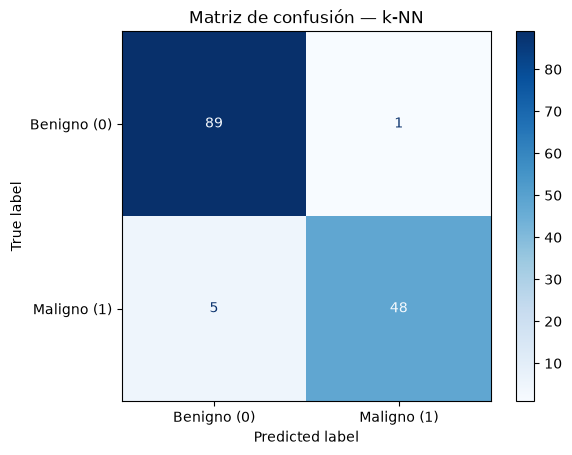

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel() # cm.ravel() aplana la matriz: convierte la tabla de 2×2 en una lista de 4 números, leyendo fila a fila, de izquierda a derecha y de arriba abajo.
print(f"\nTN = {tn}  FP = {fp}  FN = {fn}  TP = {tp}")

ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"]).plot(cmap="Blues")
plt.title("Matriz de confusión — k-NN")
plt.show()

### Ejemplo 3.2 — La matriz de confusión desenmascara al modelo tonto

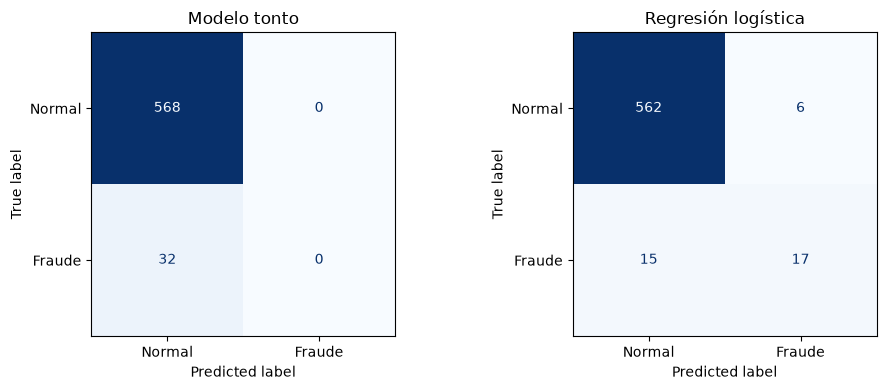

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, modelo) in zip(axes, [("Modelo tonto", tonto), ("Regresión logística", logreg_f)]):
    ConfusionMatrixDisplay.from_estimator(modelo, Xf_test, yf_test,  # ConfusionMatrixDisplay.from_estimator() hace las predicciones de Xf_test, las compara con yf_test y dibuja la matriz
                                          display_labels=["Normal", "Fraude"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

El modelo tonto tiene la columna de "Fraude" vacía: **todos los fraudes son falsos negativos**.

## 4. Precision, recall y F1

A partir de la matriz de confusión definimos tres métricas que se centran en la **clase positiva**:

**Precision (precisión):** de todo lo que el modelo dijo que era positivo, ¿cuánto lo era de verdad?
$$\text{Precision} = \frac{TP}{TP + FP}$$

**Recall (sensibilidad o exhaustividad):** de todos los positivos reales, ¿cuántos encontró el modelo?
$$\text{Recall} = \frac{TP}{TP + FN}$$

**F1:** la media armónica de las dos. Solo es alta si **ambas** lo son.
$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

**¿Cuál priorizar?** Depende de qué error sea más ***caro***:

| Problema | Error más grave | Métrica a vigilar |
|---|---|---|
| Diagnóstico de cáncer | No detectar a un enfermo (FN) | **Recall** |
| Detección de fraude | Que se escape un fraude (FN) | **Recall** |
| Filtro de spam | Mandar un correo importante a spam (FP) | **Precision** |
| Recomendar un producto caro | Molestar al cliente con algo que no quiere (FP) | **Precision** |
| No hay un error claramente peor | — | **F1** |   

Es decir (a modo de ejemplo):    

Diagnóstico de cáncer

- *FP*: se le dice a una persona sana que podría tener cáncer. Coste:*un susto y una prueba adicional que lo descarta*.
- *FN*: se le dice a una persona enferma que está sana. Coste: *no recibe tratamiento a tiempo y puede morir*.
- El FN es **mucho más caro** → queremos pocos FN → vigilamos el **Recall**.

Filtro de spam

- *FP*: un correo legítimo va a la carpeta de spam. Coste: *puedes perder la oferta de trabajo o la factura que esperabas*.
- *FN*: un correo de spam llega a la bandeja de entrada. Coste: *lo borras en un segundo*.
- El FP *es más caro* → queremos pocos FP → vigilamos la **Precision**.




### Ejemplo 4.1 — Calcularlas a mano y con scikit-learn

In [7]:
precision_mano = tp / (tp + fp)
recall_mano = tp / (tp + fn)
f1_mano = 2 * precision_mano * recall_mano / (precision_mano + recall_mano)

print(f"Precision: a mano = {precision_mano:.3f}   sklearn = {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    a mano = {recall_mano:.3f}   sklearn = {recall_score(y_test, y_pred):.3f}")
print(f"F1:        a mano = {f1_mano:.3f}   sklearn = {f1_score(y_test, y_pred):.3f}")

Precision: a mano = 0.980   sklearn = 0.980
Recall:    a mano = 0.906   sklearn = 0.906
F1:        a mano = 0.941   sklearn = 0.941


### Ejemplo 4.2 — Comparar varios modelos con todas las métricas

Volvemos al problema de fraude. Además de los dos modelos anteriores, añadimos un k-NN y un árbol de decisión.

In [8]:
modelos = {
    "Tonto (siempre 'normal')": tonto,
    "Regresión logística": logreg_f,
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xf_train, yf_train),
    "Árbol (max_depth=4)": DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xf_train, yf_train),
}

filas = []
for nombre, modelo in modelos.items():
    pred = modelo.predict(Xf_test)
    filas.append({"Modelo": nombre,
                  "Accuracy": accuracy_score(yf_test, pred),
                  "Precision": precision_score(yf_test, pred, zero_division=0), 
                  "Recall": recall_score(yf_test, pred),
                  "F1": f1_score(yf_test, pred)})
pd.DataFrame(filas).set_index("Modelo").round(3)

,Accuracy,Precision,Recall,F1
Modelo,,,,
Tonto (siempre 'normal'),0.947,0.000,0.000,0.000
Regresión logística,0.965,0.739,0.531,0.618
k-NN (k=5),0.977,1.000,0.562,0.720
Árbol (max_depth=4),0.960,0.900,0.281,0.429


Todos los modelos tienen una **accuracy** parecida, entre 0,95 y 0,98. ¿A qué se debe esto? A que la **accuracy** está dominada por la clase mayoritaria. Casi todos los aciertos de cualquier modelo vienen de clasificar bien las *operaciones normales*, y esas las aciertan prácticamente todos. 

En el test hay 600 operaciones: 568 normales y 32 fraudes. Si descomponemos los aciertos de cada modelo:

|Modelo|Normales acertadas (TN)|Fraudes acertados (TP)|	Total aciertos	|Accuracy|
|------|-----------------------|----------------------|-----------------|--------|
|Tonto|	568 de 568	| 0 de 32  |	568	|568/600 = 0,947|
|Árbol|	567 de 568	|9 de 32 |	576	|576/600 = 0,960|
|Regresión logística|	562 de 568	|17 de 32	|579 |	579/600 = 0,965|
|k-NN|	568 de 568	|18 de 32	|586	|586/600 = 0,977|     


A observar:

- La columna de *normales* es casi idéntica en todos (entre 562 y 568), y aporta más del 94 % de los aciertos.    
- Los fraudes solo pueden mover la accuracy un 5,3 % (32 de 600). Cada fraude detectado suma apenas 1/600 ≈ 0,0017. Aunque un modelo detectara todos los fraudes sin ninguna falsa alarma, su accuracy sería 1,000, solo 0,053 por encima del modelo tonto.

Por eso la accuracy de cualquier modelo sobre estos datos queda encerrada en una franja estrecha, aproximadamente entre 0,95 y 1. Las diferencias importantes quedan comprimidas en los decimales.

Si se compara el árbol con el k-NN:

- En **accuracy**: 0,960 frente a 0,977. Parecen casi iguales.
- En fraudes detectados: 9 frente a 18. **¡El k-NN detecta el doble!**

El **recall** *sí lo refleja* (0,281 frente a 0,562), porque *solo mira la clase minoritaria*: su denominador son los 32 fraudes, no las 600 operaciones. Así, *cada fraude detectado o escapado pesa mucho más en la métrica*.

Por tanto, **recall** y **F1** muestran diferencias reales en lo bien que detectan los fraudes. Por ejemplo, el árbol acierta casi siempre que dice "fraude" (**precision** alta), pero se le escapan la mayoría (**recall** bajo).    

A tener en cuenta: cuando una *clase es muy minoritaria*, la **accuracy** mide sobre todo lo bien que se acierta la clase mayoritaria. Para comparar modelos hay que mirar las métricas que se centran en la clase que nos interesa: precision, recall y F1.    

En modo práctico:     

1. Antes de evaluar, mirar la proporción de clases (`y.mean()` o `value_counts()`).
2. Si una clase es muy minoritaria y es la que nos interesa (fraudes, enfermos, averías…), la **accuracy** no sirve para comparar modelos. Todos saldrán parecidos y cerca del porcentaje de la clase mayoritaria.
3. Comparar con métricas centradas en esa clase: **recall** si no se quiere que se escapen casos, **precision** si no se quiere falsas alarmas, **F1** si se busca un equilibrio entre ambas.
4. Usar la **accuracy** como mucho para una comprobación rápida: si el modelo no supera la **accuracy** del modelo tonto, no ha aprendido nada.

> `zero_division=0` evita un aviso cuando el modelo no predice ningún positivo: en ese caso la precision sería 0/0.

## 5. `classification_report` y problemas multiclase

`classification_report` muestra precision, recall y F1 **de cada clase** de una sola vez. La columna `support` indica cuántos ejemplos reales hay de cada clase.

### Ejemplo 5.1 — Problema binario

In [8]:
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

              precision    recall  f1-score   support

     Benigno       0.95      0.99      0.97        90
     Maligno       0.98      0.91      0.94        53

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



### Ejemplo 5.2 — Problema con 3 clases (dataset Wine)

Con más de dos clases, cada clase tiene su precision, recall y F1, calculados como "esta clase frente a todas las demás". Para resumirlas en un único número hay dos promedios:
- **macro avg**: media simple. Todas las clases cuentan igual, aunque tengan pocos ejemplos.
- **weighted avg**: media ponderada por el número de ejemplos (`support`) de cada clase.

Si te importan por igual todas las clases, incluidas las minoritarias, usa **macro**.

              precision    recall  f1-score   support

     Clase 0       1.00      0.94      0.97        18
     Clase 1       0.91      1.00      0.95        21
     Clase 2       1.00      0.93      0.97        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54



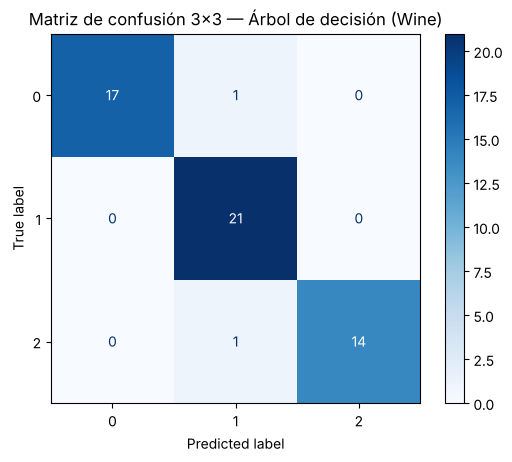

F1 macro:    0.964
F1 weighted: 0.963


In [9]:
X_w, y_w = load_wine(return_X_y=True)
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_w, y_w, test_size=0.3, stratify=y_w, random_state=42)

arbol_w = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xw_train, yw_train)
yw_pred = arbol_w.predict(Xw_test)

print(classification_report(yw_test, yw_pred, target_names=["Clase 0", "Clase 1", "Clase 2"]))

ConfusionMatrixDisplay.from_predictions(yw_test, yw_pred, cmap="Blues")
plt.title("Matriz de confusión 3×3 — Árbol de decisión (Wine)")
plt.show()

print(f"F1 macro:    {f1_score(yw_test, yw_pred, average='macro'):.3f}")
print(f"F1 weighted: {f1_score(yw_test, yw_pred, average='weighted'):.3f}")

> En multiclase, `precision_score`, `recall_score` y `f1_score` necesitan el argumento `average` (`"macro"`, `"weighted"`…).

## 6. El umbral de decisión y `predict_proba`

Los clasificadores no solo dicen una clase: pueden dar la **probabilidad** de cada clase con `predict_proba`. `predict_proba` devuelve una matriz con una fila por cada muestra de `X_test` y una columna por cada clase. En un problema binario son dos columnas:   
```
            col 0          col 1
           P(clase 0)    P(clase 1)
muestra 1    0.92          0.08
muestra 2    0.15          0.85
muestra 3    0.60          0.40
...
```    
Por defecto, `predict` asigna la clase positiva si esa probabilidad es **≥ 0,5**. Pero 0,5 no es obligatorio. **Cambiar el umbral cambia el equilibrio entre precision y recall**:
- **Umbral bajo** → el modelo dice "positivo" con más facilidad → **más recall**, menos precision.
- **Umbral alto** → solo dice "positivo" cuando está muy seguro → **más precision**, menos recall.

### Ejemplo 6.1 — Mover el umbral con una regresión logística (Breast Cancer)

In [ ]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

proba = logreg.predict_proba(X_test)[:, 1]      # probabilidad de ser MALIGNO. - Predicción, de dónde sólo tomamos la segunda columna (casos malignos)
print("Probabilidades de los 5 primeros casos:", np.round(proba[:5], 3))

filas = []
for umbral in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (proba >= umbral).astype(int) # Comparamos cada probabilidad con el umbral y, según el resultado, establecemos si es o no maligno.
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Umbral": umbral, "FP (falsas alarmas)": fp, "FN (malignos no detectados)": fn,
                  "Precision": round(precision_score(y_test, pred), 3),
                  "Recall": round(recall_score(y_test, pred), 3)})
pd.DataFrame(filas).set_index("Umbral")

Probabilidades de los 5 primeros casos: [0.999 0.004 1.    0.    0.035]


,FP (falsas alarmas),FN (malignos no detectados),Precision,Recall
Umbral,,,,
0.1,6,1,0.897,0.981
0.3,1,2,0.981,0.962
0.5,1,4,0.980,0.925
0.7,0,5,1.000,0.906
0.9,0,10,1.000,0.811


En un diagnóstico médico preferiríamos un umbral **bajo**: aceptamos más falsas alarmas, que se descartan con otra prueba, a cambio de que no se escape ningún tumor maligno.

### Ejemplo 6.2 — Visualizar el compromiso precision–recall

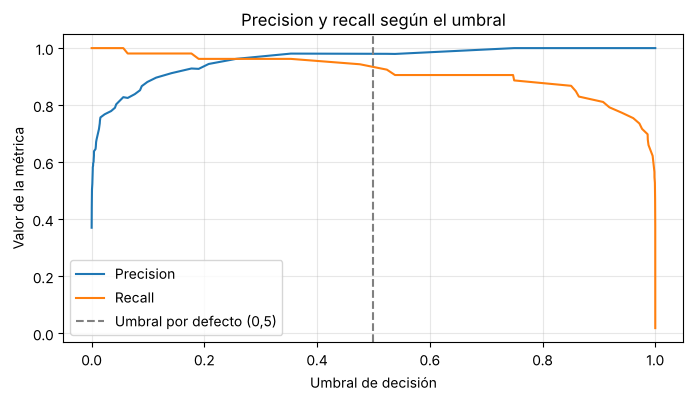

In [11]:
precisiones, recalls, umbrales = precision_recall_curve(y_test, proba)

plt.figure(figsize=(8, 4))
plt.plot(umbrales, precisiones[:-1], label="Precision")
plt.plot(umbrales, recalls[:-1], label="Recall")
plt.axvline(0.5, color="gray", linestyle="--", label="Umbral por defecto (0,5)")
plt.xlabel("Umbral de decisión")
plt.ylabel("Valor de la métrica")
plt.title("Precision y recall según el umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Curva ROC y AUC

La curva **ROC** muestra el comportamiento del modelo **con todos los umbrales a la vez**. Ayuda a visualizar cómo cambia el rendimiento del modelo al variar ese umbral. Para cada umbral dibuja:
- En el eje Y: la **tasa de verdaderos positivos** (TPR), que es el recall.
- En el eje X: la **tasa de falsos positivos** (FPR) = FP / (FP + TN), es decir, qué proporción de negativos se marcan erróneamente como positivos.

El **AUC** (*area under the curve*) es el área bajo esa curva y refleja la capacidad general del modelo para discriminar entre clases:
- **AUC = 1**: modelo perfecto.
- **AUC = 0,5**: el modelo no distingue nada, como tirar una moneda (la diagonal).
- Interpretación intuitiva: es la probabilidad de que el modelo dé una puntuación más alta a un positivo elegido al azar que a un negativo elegido al azar.

**Ventaja:** no depende del umbral, así que sirve para **comparar modelos** en general.


La curva ROC es un gráfico que muestra qué tan bien funciona un modelo para separar las clases. En el eje horizontal aparece la tasa de falsos positivos, es decir, cuándo el modelo se equivoca. En el eje vertical está la tasa de verdaderos positivos, es decir, los positivos detectados correctamente.    

Si la curva sube rápidamente y se acerca a la esquina superior izquierda, eso significa que el modelo es muy preciso, detecta bien a los verdaderos positivos y comete pocos errores. Pero si la curva está cerca de la diagonal, indica que el modelo no es mejor que adivinar al azar. 

El **área bajo la curva (AUC)** mide qué tan buena es esta separación, donde un valor de 1 significa que el modelo es perfecto y 0.5 que no aporta nada.
En la curva que vemos, *la línea azul sube rápido al principio y luego se aplana*, lo que indica que e*l modelo detecta la mayoría de casos reales sin aumentar demasiado los falsos positivos*. El AUC cercano a 1 confirma que *el modelo es fiable y se puede usar para apoyar decisiones médicas*.


> Para calcular ROC y AUC hacen falta **probabilidades** (`predict_proba`), no las clases predichas.

### Ejemplo 7.1 — Comparar cuatro modelos con la curva ROC (Breast Cancer)

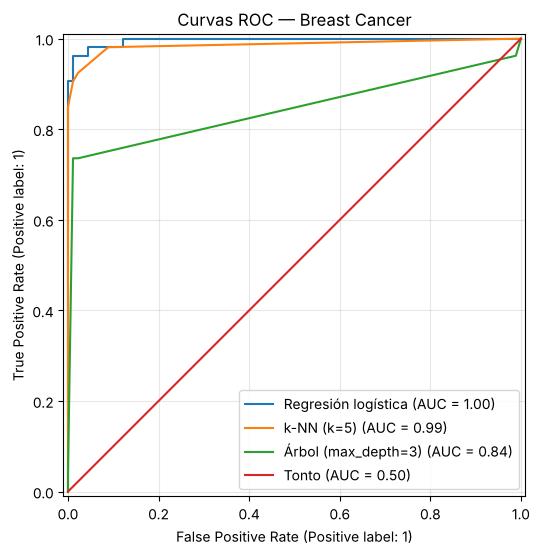

Regresión logística    AUC = 0.996
k-NN (k=5)             AUC = 0.986
Árbol (max_depth=3)    AUC = 0.844
Tonto                  AUC = 0.500


In [12]:
modelos_bc = {
    "Regresión logística": logreg,
    "k-NN (k=5)": knn,
    "Árbol (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train),
    "Tonto": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
}

fig, ax = plt.subplots(figsize=(6, 6))
for nombre, modelo in modelos_bc.items():
    RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=nombre, ax=ax)
ax.set_title("Curvas ROC — Breast Cancer")
ax.grid(alpha=0.3)
plt.show()

for nombre, modelo in modelos_bc.items():
    auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
    print(f"{nombre:22s} AUC = {auc:.3f}")

La curva que más se acerca a la esquina superior izquierda es la del mejor modelo. El modelo tonto queda en la diagonal (AUC = 0,5).

Fíjate en que el árbol tiene una curva "a escalones". Un árbol poco profundo solo puede dar unas pocas probabilidades distintas, una por cada hoja.

### Ejemplo 7.2 — Con clases muy desequilibradas: la curva Precision-Recall

Con muchos negativos, la FPR se mantiene baja aunque haya bastantes falsas alarmas, porque el denominador (FP + TN) es enorme. Por eso el AUC-ROC puede parecer muy bueno aunque la precision sea mediocre.

En esos casos es más informativa la **curva Precision-Recall**. Su área se llama **average precision (AP)**. Su valor de referencia (modelo al azar) ya no es 0,5, sino la **proporción de positivos**: en nuestro problema de fraude, alrededor de 0,05.

AUC-ROC:           0.930
Average precision: 0.713
Proporción de positivos (referencia del azar en la curva PR): 0.053


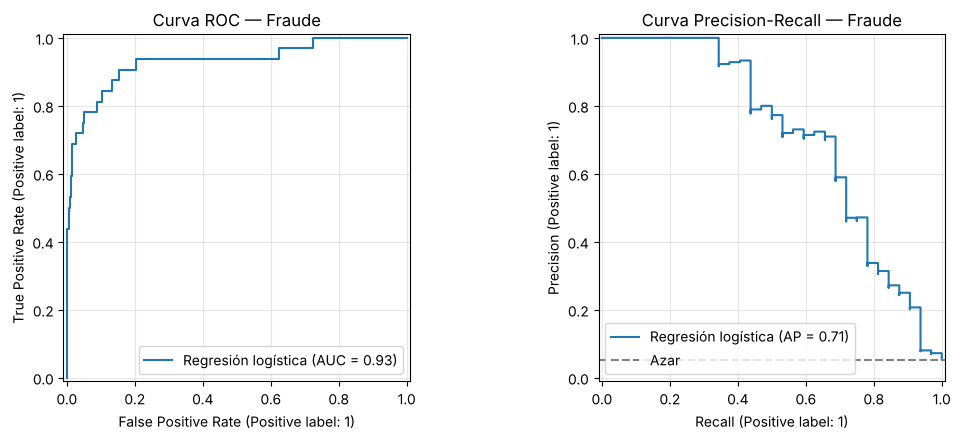

In [13]:
proba_f = logreg_f.predict_proba(Xf_test)[:, 1]
print(f"AUC-ROC:           {roc_auc_score(yf_test, proba_f):.3f}")
print(f"Average precision: {average_precision_score(yf_test, proba_f):.3f}")
print(f"Proporción de positivos (referencia del azar en la curva PR): {yf_test.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(yf_test, proba_f, ax=axes[0], name="Regresión logística")
axes[0].set_title("Curva ROC — Fraude")
PrecisionRecallDisplay.from_predictions(yf_test, proba_f, ax=axes[1], name="Regresión logística")
axes[1].axhline(yf_test.mean(), color="gray", linestyle="--", label="Azar")
axes[1].legend()
axes[1].set_title("Curva Precision-Recall — Fraude")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El AUC-ROC sale bastante más alto que la average precision. La curva Precision-Recall muestra con más realismo lo difícil que es detectar fraudes sin generar muchas falsas alarmas.

### Resumen de métricas de clasificación

| Métrica | Pregunta que responde | Cuándo usarla |
|---|---|---|
| Accuracy | ¿Qué proporción acierto? | Clases equilibradas y errores con el mismo coste |
| Precision | Cuando digo "positivo", ¿acierto? | Los falsos positivos son caros |
| Recall | ¿Encuentro todos los positivos? | Los falsos negativos son caros |
| F1 | Equilibrio entre precision y recall | Clases desequilibradas, sin un error claramente peor |
| AUC-ROC | ¿Ordena bien positivos y negativos, sea cual sea el umbral? | Comparar modelos, clases razonablemente equilibradas |
| Average precision | Igual, pero centrada en la clase positiva | Clases muy desequilibradas |

---
# PARTE B: Métricas de regresión

En regresión no hay "acierto" o "fallo": siempre hay un **error** (o **residuo**), que es la diferencia entre el valor real y el predicho:

$$e_i = y_i - \hat{y}_i$$

Las métricas de regresión resumen todos esos errores en un número.

## 8. MAE, MSE y RMSE

**MAE** (*Mean Absolute Error*, error absoluto medio): la media de los errores en valor absoluto.
$$MAE = \frac{1}{n}\sum |y_i - \hat{y}_i|$$
- Se expresa en las **mismas unidades** que la variable objetivo (euros, grados…). Es muy fácil de interpretar.

**MSE** (*Mean Squared Error*, error cuadrático medio): la media de los errores al cuadrado.
$$MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$$
- Está en **unidades al cuadrado** (euros²), así que es difícil de interpretar.
- Al elevar al cuadrado, **castiga mucho los errores grandes**.

**RMSE** (*Root Mean Squared Error*): la raíz cuadrada del MSE.
$$RMSE = \sqrt{MSE}$$
- Vuelve a las **unidades originales** y mantiene el castigo a los errores grandes.

En las tres, **cuanto más bajo, mejor** (0 = perfecto).

### Ejemplo 8.1 — Calcularlas a mano con 5 datos

In [14]:
y_real = np.array([3.0, 5.0, 2.0, 7.0, 4.0])
y_pred_r = np.array([2.5, 5.0, 4.0, 8.0, 4.0])

errores = y_real - y_pred_r
print("Errores:          ", errores)
print("Errores absolutos:", np.abs(errores))
print("Errores al cuadr.:", errores ** 2)

print(f"\nMAE  = {np.mean(np.abs(errores)):.3f}   sklearn: {mean_absolute_error(y_real, y_pred_r):.3f}")
print(f"MSE  = {np.mean(errores ** 2):.3f}   sklearn: {mean_squared_error(y_real, y_pred_r):.3f}")
print(f"RMSE = {np.sqrt(np.mean(errores ** 2)):.3f}   sklearn: {root_mean_squared_error(y_real, y_pred_r):.3f}")

Errores:           [ 0.5  0.  -2.  -1.   0. ]
Errores absolutos: [0.5 0.  2.  1.  0. ]
Errores al cuadr.: [0.25 0.   4.   1.   0.  ]

MAE  = 0.700   sklearn: 0.700
MSE  = 1.050   sklearn: 1.050
RMSE = 1.025   sklearn: 1.025


### Ejemplo 8.2 — MAE vs. RMSE: ¿cómo tratan los errores grandes?

Dos modelos con el **mismo MAE**:
- El modelo A se equivoca un poco en todos los casos.
- El modelo B acierta casi todo, pero tiene **un error enorme**.

In [15]:
y_real = np.array([10, 10, 10, 10, 10])
pred_A = np.array([12, 8, 12, 8, 12])     # errores: 2, 2, 2, 2, 2
pred_B = np.array([10, 10, 10, 10, 20])   # errores: 0, 0, 0, 0, 10

for nombre, pred in [("Modelo A (errores pequeños y repartidos)", pred_A),
                     ("Modelo B (un error muy grande)", pred_B)]:
    print(f"{nombre:42s} MAE = {mean_absolute_error(y_real, pred):.2f}   "
          f"RMSE = {root_mean_squared_error(y_real, pred):.2f}")

Modelo A (errores pequeños y repartidos)   MAE = 2.00   RMSE = 2.00
Modelo B (un error muy grande)             MAE = 2.00   RMSE = 4.47


- El **MAE** trata igual a los dos modelos.
- El **RMSE** penaliza mucho más al modelo B por su gran error.

**¿Cuál usar?**
- **MAE**: si todos los errores importan por igual o hay **valores atípicos** (*outliers*) que no deben dominar la métrica.
- **RMSE**: si un error grande es **especialmente grave**. Por ejemplo, prever la demanda eléctrica: quedarse muy corto un día puede provocar un apagón.

## 9. R² (coeficiente de determinación) y MAPE

### R²

Compara nuestro modelo con un modelo de referencia muy simple: **predecir siempre la media** de `y`.

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2} = 1 - \frac{\text{error de mi modelo}}{\text{error de predecir siempre la media}}$$

- **R² = 1**: predicciones perfectas.
- **R² = 0**: el modelo no es mejor que predecir siempre la media.
- **R² < 0**: ¡el modelo es **peor** que predecir la media!

Se suele interpretar como la **proporción de la variabilidad de `y` que explica el modelo**. Ventaja: no tiene unidades, así que siempre se mueve en la misma escala.

### MAPE (*Mean Absolute Percentage Error*)

Es el error medio **en porcentaje** respecto al valor real:
$$MAPE = \frac{1}{n}\sum \left|\frac{y_i - \hat{y}_i}{y_i}\right|$$

Es fácil de comunicar ("nos equivocamos un 15 % de media"), pero **falla si hay valores reales cercanos a 0** (división por casi cero). `scikit-learn` lo devuelve como fracción (0,15 = 15 %).

### Ejemplo 9.1 — Comparar modelos de regresión (dataset Diabetes)

El objetivo es una medida numérica de la progresión de la diabetes un año después. Comparamos cuatro modelos, incluido un `DummyRegressor` que siempre predice la media.

In [16]:
X_d, y_d = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.25, random_state=42)
print(f"Rango de y: de {y_d.min():.0f} a {y_d.max():.0f}   Media: {y_d.mean():.1f}\n")

modelos_reg = {
    "Tonto (predice la media)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "k-NN (k=10)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Árbol (max_depth=3)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Árbol (sin límite)": DecisionTreeRegressor(random_state=42),
}

filas = []
for nombre, modelo in modelos_reg.items():
    modelo.fit(Xd_train, yd_train)
    pred = modelo.predict(Xd_test)
    filas.append({"Modelo": nombre,
                  "MAE": mean_absolute_error(yd_test, pred),
                  "RMSE": root_mean_squared_error(yd_test, pred),
                  "MAPE (%)": 100 * mean_absolute_percentage_error(yd_test, pred),
                  "R²": r2_score(yd_test, pred)})
tabla_reg = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla_reg

Rango de y: de 25 a 346   Media: 152.1



,MAE,RMSE,MAPE (%),R²
Modelo,,,,
Tonto (predice la media),65.527,74.881,64.315,-0.014
Regresión lineal,41.549,53.370,37.311,0.485
k-NN (k=10),43.879,55.147,39.076,0.450
Árbol (max_depth=3),46.912,59.258,43.148,0.365
Árbol (sin límite),58.838,77.082,51.662,-0.075


Cómo leer la tabla:
- El **modelo tonto** tiene un R² de prácticamente 0: es la referencia. Puede salir ligeramente negativo porque la media se calcula con el entrenamiento, no con el test.
- La **regresión lineal** consigue el mejor resultado en todas las métricas.
- El **árbol sin límite de profundidad** memoriza el entrenamiento (**sobreajuste**) y en test queda peor que el modelo tonto: su R² es negativo.
- MAE y RMSE se leen en las unidades de `y`. Por ejemplo, un MAE de 42 significa que, de media, nos equivocamos en unas 42 unidades.

### Ejemplo 9.2 — Sobreajuste visto con las métricas: train vs. test

Comparar la métrica en **entrenamiento** y en **test** es la forma más sencilla de detectar sobreajuste.

In [17]:
for profundidad in [1, 3, 5, 10, None]:
    arbol = DecisionTreeRegressor(max_depth=profundidad, random_state=42).fit(Xd_train, yd_train)
    r2_train = r2_score(yd_train, arbol.predict(Xd_train))
    r2_test = r2_score(yd_test, arbol.predict(Xd_test))
    print(f"max_depth = {str(profundidad):4s}  R² train = {r2_train:6.3f}   R² test = {r2_test:6.3f}")

max_depth = 1     R² train =  0.290   R² test =  0.215
max_depth = 3     R² train =  0.510   R² test =  0.365
max_depth = 5     R² train =  0.687   R² test =  0.283
max_depth = 10    R² train =  0.959   R² test =  0.094
max_depth = None  R² train =  1.000   R² test = -0.075


Cuanto más profundo es el árbol, mejor le va en entrenamiento (llega a R² = 1) y peor en test. Una gran diferencia entre train y test es la señal típica del **sobreajuste**.

## 10. Gráficos para diagnosticar errores

Un número resume, pero **esconde detalles**. Dos gráficos muy útiles:

1. **Real vs. predicho**: si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal.
2. **Residuos vs. predicho**: los errores deberían estar repartidos al azar alrededor de 0, sin formas ni patrones.
   - Si se ve una curva → el modelo no capta alguna relación no lineal.
   - Si los errores se abren en forma de embudo → el modelo se equivoca más con valores grandes.

### Ejemplo 10.1 — Diagnóstico de la regresión lineal

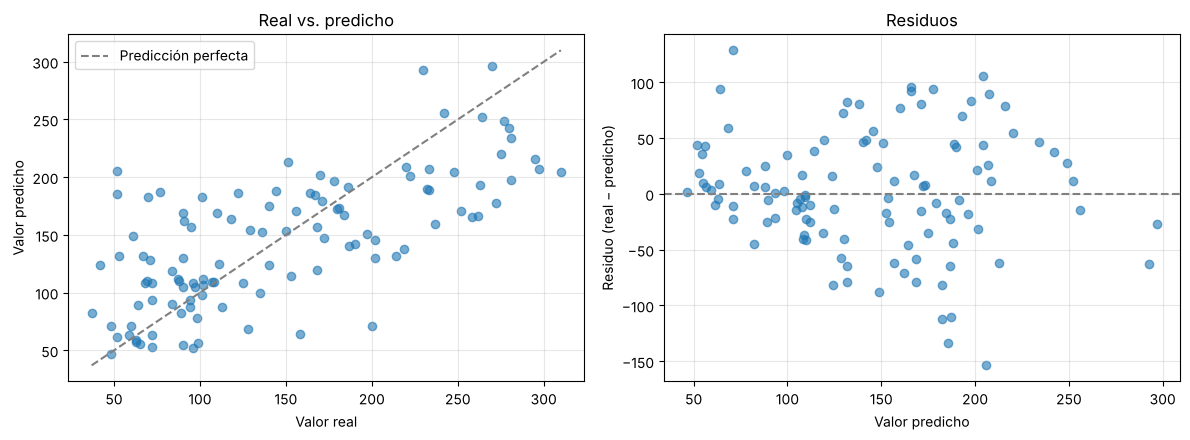

In [18]:
reg = LinearRegression().fit(Xd_train, yd_train)
pred = reg.predict(Xd_test)
residuos = yd_test - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(yd_test, pred, alpha=0.6)
lims = [min(yd_test.min(), pred.min()), max(yd_test.max(), pred.max())]
axes[0].plot(lims, lims, color="gray", linestyle="--", label="Predicción perfecta")
axes[0].set_xlabel("Valor real")
axes[0].set_ylabel("Valor predicho")
axes[0].set_title("Real vs. predicho")
axes[0].legend()

axes[1].scatter(pred, residuos, alpha=0.6)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Valor predicho")
axes[1].set_ylabel("Residuo (real − predicho)")
axes[1].set_title("Residuos")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Los puntos siguen la diagonal pero con bastante dispersión, como corresponde a un R² moderado. Los residuos no muestran un patrón claro, así que el modelo lineal no está pasando por alto ninguna relación evidente.

### Resumen de métricas de regresión

| Métrica | Unidades | Mejor valor | Característica principal |
|---|---|---|---|
| MAE | Las de `y` | 0 | Fácil de interpretar, robusta ante outliers |
| MSE | Las de `y` al cuadrado | 0 | Castiga mucho los errores grandes; difícil de interpretar |
| RMSE | Las de `y` | 0 | Como el MSE, pero en unidades interpretables |
| R² | Sin unidades | 1 | Compara con predecir la media; puede ser negativo |
| MAPE | Porcentaje | 0 | Fácil de comunicar; falla si `y` tiene valores cercanos a 0 |

---
# PARTE C: Métricas en la práctica

## 11. Métricas en validación cruzada y en la búsqueda de hiperparámetros

Hasta ahora hemos medido sobre un único conjunto de test. Como vimos en el cuaderno anterior, es más fiable usar **validación cruzada**. Para elegir la métrica se usa el argumento `scoring`, con un texto:

| Clasificación | Regresión |
|---|---|
| `"accuracy"` | `"r2"` |
| `"precision"`, `"recall"`, `"f1"` | `"neg_mean_absolute_error"` |
| `"f1_macro"`, `"f1_weighted"` (multiclase) | `"neg_mean_squared_error"` |
| `"roc_auc"` | `"neg_root_mean_squared_error"` |
| `"average_precision"` | `"neg_mean_absolute_percentage_error"` |

> **¿Por qué `neg_`?** scikit-learn siempre **maximiza** la puntuación (más alto = mejor). Como en los errores lo bueno es que sean bajos, los devuelve **cambiados de signo**. Para interpretarlos basta con quitar el signo menos.

### Ejemplo 11.1 — Varias métricas a la vez con `cross_validate`

`cross_val_score` solo admite una métrica; `cross_validate` admite varias.

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

res = cross_validate(modelo, X, y, cv=skf,
                     scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

pd.DataFrame({m: res[f"test_{m}"] for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
             index=[f"Fold {i}" for i in range(1, 6)]).round(3).T.assign(
    Media=lambda d: d.mean(axis=1).round(3))

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Media
accuracy,0.974,0.947,0.965,0.991,0.991,0.974
precision,0.955,1.000,1.000,0.977,1.000,0.986
recall,0.977,0.860,0.905,1.000,0.976,0.944
f1,0.966,0.925,0.950,0.988,0.988,0.963
roc_auc,0.995,0.998,0.985,1.000,0.999,0.995


### Ejemplo 11.2 — Regresión: ojo con el signo

In [20]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(LinearRegression(), X_d, y_d, cv=kf,
                     scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])

print("neg_MAE por fold:", np.round(res["test_neg_mean_absolute_error"], 1))
print(f"MAE medio:  {-res['test_neg_mean_absolute_error'].mean():.1f}   ← le quitamos el signo")
print(f"RMSE medio: {-res['test_neg_root_mean_squared_error'].mean():.1f}")
print(f"R² medio:   {res['test_r2'].mean():.3f}")

neg_MAE por fold: [-42.8 -41.6 -47.2 -42.1 -47.6]
MAE medio:  44.3   ← le quitamos el signo
RMSE medio: 54.8
R² medio:   0.478


### Ejemplo 11.3 — La métrica elegida cambia el modelo que gana

En `GridSearchCV`, el `scoring` decide **qué combinación se considera la mejor**. Volvemos al problema de fraude y buscamos hiperparámetros para una regresión logística:
- `C`: la regularización, que ya conocemos.
- `class_weight`: con `"balanced"`, los errores en la clase minoritaria (fraude) **cuentan más** durante el entrenamiento. Con `None`, todos los errores cuentan igual.

Repetimos la búsqueda optimizando tres métricas distintas.

In [21]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10],
    "logisticregression__class_weight": [None, "balanced"],
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []
for metrica in ["accuracy", "recall", "f1"]:
    grid = GridSearchCV(pipe, param_grid, cv=skf, scoring=metrica).fit(Xf_train, yf_train)
    pred = grid.predict(Xf_test)
    tn, fp, fn, tp = confusion_matrix(yf_test, pred).ravel()
    filas.append({"Optimizando": metrica,
                  "C elegido": grid.best_params_["logisticregression__C"],
                  "class_weight elegido": str(grid.best_params_["logisticregression__class_weight"]),
                  "Fraudes detectados (TP)": tp, "Fraudes escapados (FN)": fn,
                  "Falsas alarmas (FP)": fp,
                  "Precision test": round(precision_score(yf_test, pred), 3),
                  "Recall test": round(recall_score(yf_test, pred), 3)})
pd.DataFrame(filas).set_index("Optimizando")

,C elegido,class_weight elegido,Fraudes detectados (TP),Fraudes escapados (FN),Falsas alarmas (FP),Precision test,Recall test
Optimizando,,,,,,,
accuracy,0.10,None,12,20,1,0.923,0.375
recall,0.01,balanced,27,5,86,0.239,0.844
f1,10.00,None,17,15,6,0.739,0.531


- Optimizando **accuracy**, la búsqueda elige un modelo que deja escapar muchos fraudes, porque acertar los casos normales ya da una accuracy muy alta.
- Optimizando **recall**, elige `class_weight="balanced"`: detecta la gran mayoría de los fraudes, a costa de muchísimas falsas alarmas.
- **F1** busca un punto intermedio.

**Ninguna opción es "la correcta" en abstracto.** La métrica debe reflejar **qué le importa al problema real**, y conviene decidirla **antes** de entrenar.

## 12. Resumen y errores frecuentes

**¿Qué métrica uso?**

```
¿Predigo una categoría o un número?
│
├── Categoría (CLASIFICACIÓN)
│   ├── Clases equilibradas y errores de igual coste      → accuracy (+ matriz de confusión)
│   ├── Los falsos negativos son caros (enfermo, fraude)  → recall
│   ├── Los falsos positivos son caros (spam)             → precision
│   ├── Clases desequilibradas, sin error claramente peor → F1
│   ├── Comparar modelos sin fijar umbral                 → AUC-ROC
│   └── Clases muy desequilibradas                        → average precision (curva PR)
│
└── Número (REGRESIÓN)
    ├── Error fácil de interpretar, robusto a outliers → MAE
    ├── Los errores grandes son especialmente graves    → RMSE
    ├── Comparar con "predecir la media" / sin unidades → R²
    └── Comunicar el error en porcentaje                → MAPE (si y no se acerca a 0)
```

**Errores frecuentes**
- Fiarse solo de la **accuracy** con clases desequilibradas. Compara siempre con un `DummyClassifier`.
- Confundir cuál es la **clase positiva**: precision, recall y F1 se calculan sobre la clase `1` por defecto (argumento `pos_label`).
- Calcular el AUC con `predict` en lugar de con `predict_proba`.
- Olvidar `average=` en problemas multiclase.
- Comparar el MAE o el RMSE de **problemas distintos**: dependen de las unidades de `y`. El R² sí es comparable.
- Interpretar `neg_mean_absolute_error` como si un número "más negativo" fuera mejor. Es al revés.
- Medir sobre los datos de **entrenamiento**: siempre test o validación cruzada.

## 13. Ejercicios propuestos

1. **Accuracy y modelo tonto**: con `load_breast_cancer` (con `y = 1 - y`), compara la accuracy de un `DummyClassifier(strategy="most_frequent")` con la de un árbol de decisión de `max_depth=3`. ¿Supera claramente el árbol al modelo tonto?
2. **Matriz de confusión**: entrena un k-NN con k = 1, 5 y 25 sobre Breast Cancer. Para cada uno, dibuja la matriz de confusión y calcula precision y recall a mano a partir de TP, FP y FN.
3. **Umbral**: con la regresión logística del ejemplo 6.1, busca el umbral más alto que consiga un recall de al menos 0,98. ¿Cuántas falsas alarmas provoca?
4. **Multiclase**: con `load_wine`, compara `f1_macro` y `f1_weighted` de una regresión logística (con escalado) y de un k-NN usando `cross_validate`.
5. **Regresión**: con `load_diabetes`, calcula MAE, RMSE y R² con validación cruzada (`cv=10`) para k-NN con k = 1, 5, 10, 20 y 50. Dibuja cómo cambia el R² medio con k.
6. **GridSearchCV**: repite el ejemplo 11.3 con un árbol de decisión (`max_depth` de 2 a 8 y `class_weight` `None` o `"balanced"`). ¿Cambia el modelo elegido según la métrica?

In [22]:
# Espacio para los ejercicios